In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent  # project root (notebooks/ sits one level below)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True)
df = data.frame

print(df.shape)
display(df.head())
display(df.describe().T)

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
print("Baseline RMSE:", root_mean_squared_error(y_test, baseline.predict(X_test)))


Baseline RMSE: 1.1448563543099792


In [4]:
print("Missing Values:", X_train.isna().sum())
print(X_train.skew().sort_values(ascending=False))

skewed = ["AveRooms", "AveBedrms", "Population", "AveOccup"]
display(X_train[skewed].describe(percentiles=[.01, .99]).T)

Missing Values: MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64
AveOccup      88.052663
AveBedrms     23.170746
AveRooms      18.607090
Population     5.276131
MedInc         1.634090
Latitude       0.461504
HouseAge       0.063453
Longitude     -0.288418
dtype: float64


,count,mean,std,min,1%,50%,99%,max
AveRooms,16512.0,5.435235,2.387375,0.888889,2.578195,5.235874,10.318432,141.909091
AveBedrms,16512.0,1.096685,0.433215,0.333333,0.871161,1.049286,2.116536,25.636364
Population,16512.0,1426.453004,1137.056380,3.000000,88.110000,1167.000000,5798.720000,35682.000000
AveOccup,16512.0,3.096961,11.578744,0.692308,1.538838,2.817240,5.410157,1243.333333


In [5]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import Ridge

others = [c for c in X_train.columns if c not in skewed]

log_scale = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler())
])

preprocess = ColumnTransformer([
    ("skewed", log_scale, skewed),
    ("rest", StandardScaler(), others)
])

ridge = Pipeline([
    ("prep", preprocess), ("model", Ridge(alpha=1.0))
    ])

ridge.fit(X_train, y_train)
print("Ridge MSE:", root_mean_squared_error(y_test, ridge.predict(X_test)))


Ridge MSE: 0.6832665000927511


In [6]:
from housing.features import add_features

new_feats = ["BedroomRatio", "RoomsPerPerson", "DistSF", "DistLA"]

preprocess_fe = ColumnTransformer([
    ("skewed", log_scale, skewed),
    ("rest", StandardScaler(), others + new_feats)
])

ridge_fe = Pipeline([
    ("fe", FunctionTransformer(add_features)),
    ("prep", preprocess_fe),
    ("model", Ridge(alpha=1.0))
])

ridge_fe.fit(X_train, y_train)
print("Ridge + FE RMSE:", root_mean_squared_error(y_test, ridge_fe.predict(X_test)))

Ridge + FE RMSE: 0.6773643368885527


In [7]:
import pandas as pd
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

def make_pipe(model):
    return Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("prep", preprocess_fe),
        ("model", model)
    ])

models = {
    "ridge": Ridge(alpha=1.0),
    "lasso": Lasso(alpha=0.001),
    "rf": RandomForestRegressor(n_estimators=200, random_state=42),
    "hgb": HistGradientBoostingRegressor(random_state=42)
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    res = cross_validate(
        make_pipe(m), X_train, y_train, cv=cv,
        scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    rmse = -res["test_score"]
    rows.append({"model":name, "rmse_mean":rmse.mean(), "rmse_std": rmse.std()})


display(pd.DataFrame(rows).sort_values("rmse_mean"))


,model,rmse_mean,rmse_std
3,hgb,0.461610,0.009156
2,rf,0.491955,0.011402
0,ridge,0.665840,0.016817
1,lasso,0.665982,0.017053


In [8]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "model__learning_rate": loguniform(0.02, 0.3),
    "model__max_iter": randint(200, 800),
    "model__max_leaf_nodes": randint(15, 80),
    "model__min_samples_leaf": randint(10, 60),
    "model__l2_regularization": loguniform(1e-3, 10),
}

search = RandomizedSearchCV(
    make_pipe(HistGradientBoostingRegressor(random_state=42)),
    param_distributions=param_dist,
    n_iter=25, cv=cv, scoring='neg_root_mean_squared_error',
    random_state=42, n_jobs=-1
)

search.fit(X_train, y_train)
print("Best CV RMSE:", -search.best_score_)
print(search.best_params_)

# refit via the module-based add_features so the pipeline pickles by import path
best_model = make_pipe(HistGradientBoostingRegressor(random_state=42))
best_model.set_params(**search.best_params_)
best_model.fit(X_train, y_train)

Best CV RMSE: 0.4503667889557351
{'model__l2_regularization': 0.2975390947349387, 'model__learning_rate': 0.056343030242230155, 'model__max_iter': 443, 'model__max_leaf_nodes': 78, 'model__min_samples_leaf': 12}


,steps,"[('fe', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function add...t 0x139a86200>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,None
,kw_args,None


RMSE: 0.44038695315325427
MAE:  0.283873880651552
R2:   0.8519998933707295


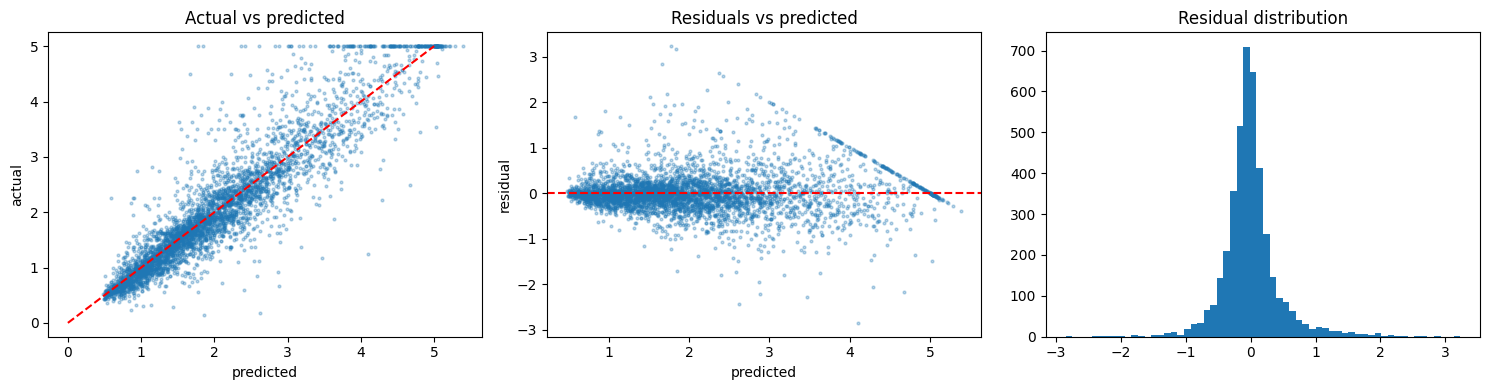

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

pred = best_model.predict(X_test)
resid = y_test - pred

print("RMSE:", root_mean_squared_error(y_test, pred))
print("MAE: ", mean_absolute_error(y_test, pred))
print("R2:  ", r2_score(y_test, pred))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(pred, y_test, s=4, alpha=0.3)
ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set(xlabel="predicted", ylabel="actual", title="Actual vs predicted")

ax[1].scatter(pred, resid, s=4, alpha=0.3)
ax[1].axhline(0, color="r", ls="--")
ax[1].set(xlabel="predicted", ylabel="residual", title="Residuals vs predicted")

ax[2].hist(resid, bins=60)
ax[2].set(title="Residual distribution")
plt.tight_layout()


In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.isotonic import IsotonicRegression

oof_pred = cross_val_predict(best_model, X_train, y_train, cv=cv, n_jobs=-1)

oof = pd.DataFrame({"pred": oof_pred, "actual": y_train.values})
oof["bin"] = pd.qcut(oof["pred"], 10)

oof_tbl = oof.groupby("bin", observed=True).agg(
    mean_pred=("pred", "mean"),
    mean_actual=("actual", "mean"),
)
oof_tbl["bias"] = oof_tbl["mean_actual"] - oof_tbl["mean_pred"]
display(oof_tbl)


,mean_pred,mean_actual,bias
bin,,,
"(0.372, 0.895]",0.725106,0.724580,-0.000526
"(0.895, 1.152]",1.025567,1.016569,-0.008997
"(1.152, 1.395]",1.277061,1.251930,-0.025131
"(1.395, 1.611]",1.503518,1.489662,-0.013856
"(1.611, 1.843]",1.724377,1.747785,0.023408
"(1.843, 2.1]",1.966854,1.984082,0.017228
"(2.1, 2.432]",2.259003,2.271612,0.012609
"(2.432, 2.875]",2.633078,2.635947,0.002869
"(2.875, 3.65]",3.227310,3.229533,0.002224


In [11]:
alpha = 0.1
abs_res = np.abs(y_train.values - oof_pred)
n = len(abs_res)
q = np.quantile(abs_res, np.ceil((n + 1) * (1 - alpha)) / n)

lower, upper = pred - q, pred + q
covered = (y_test.values >= lower) & (y_test.values <= upper)
print(f"Interval widtg: {2 * q:.3f}, coverage : {covered.mean():.3f}")

cov_by_bin = pd.Series(covered).groupby(pd.qcut(pred, 10)).mean()
display(cov_by_bin)

Interval widtg: 1.346, coverage : 0.905


/var/folders/0l/p7lzlqxn44b036b_3ykx4tlr0000gn/T/ipykernel_14662/1961394725.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cov_by_bin = pd.Series(covered).groupby(pd.qcut(pred, 10)).mean()


(0.477, 0.891]    0.992736
(0.891, 1.14]     0.978208
(1.14, 1.391]     0.983051
(1.391, 1.613]    0.961165
(1.613, 1.835]    0.910412
(1.835, 2.104]    0.920097
(2.104, 2.409]    0.895631
(2.409, 2.863]    0.857143
(2.863, 3.619]    0.765133
(3.619, 5.387]    0.784504
dtype: float64

In [ ]:
import mlflow
from mlflow.models import infer_signature

EXPERIMENT = "housing-price-regression"
mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")

# artifacts default to ./mlruns relative to cwd, so pin them to the project root
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=(ROOT / "mlruns").as_uri())
mlflow.set_experiment(EXPERIMENT)

with mlflow.start_run(run_name="hgb-tuned") as run:
    mlflow.log_params(search.best_params_)
    mlflow.log_metric("cv_rmse", -search.best_score_)
    mlflow.log_metrics({
        "test_rmse": root_mean_squared_error(y_test, pred),
        "test_mae": mean_absolute_error(y_test, pred),
        "test_r2": r2_score(y_test, pred),
    })

    signature = infer_signature(X_train, best_model.predict(X_train))
    mlflow.sklearn.log_model(
        best_model, name="model",
        signature=signature, input_example=X_train.head(5),
    )
    print("run_id:", run.info.run_id)
